### **Student Information**
GitHub ID: locngohpe1 (ID: 188996066)

Kaggle name: Jennie (Team Jaden and friends)

Kaggle private scoreboard snapshot:

![pic_ranking.png](./pics/pic_ranking.png)

*Your name and student ID are deliberately not asked for here: this notebook goes into your repository, which is public. They belong in the git-ignored `config/.env`, where the other two notebooks read them from, and your NTU COOL submission is what ties the repository link back to you.*

---

# **Instructions**

This lab has **three parts**: exercises in the Master notebook, exercises and an agent conversation in the AgentPipeline notebook, and an internal Kaggle competition documented in this Homework notebook. Together they add up to **100 points**.

**Environment recommendations to solve lab 2:**
- **Part 1 and 2 exercises:** Everything can be run with only CPU.
- **Part 3 exercises:** For the competition you will probably need GPU to train your models, so it is recommended to use Colab or Kaggle if you don't have a laptop with a dedicated GPU.

## **Part 1 (40 pts):**

1. __Main Exercises (35 pts):__ Do the **take home exercises** from Sections: `1. Data Preparation` to `8. Information Retrieval and RAG`, in the DM2026-Lab2-Master Notebook. Total: `13 exercises`. Commit your code and submit the repository link to NTU Cool.

2. **Code Comments (5 pts):** **Tidy up the code in your notebook**.

## **Part 2 (30 pts):**

1. **Agent Prompt (20 pts):** Interact with the Agent using appropriate prompts to guide it through and complete all the required tasks.

2. **Main Exercises (10 pts):** Do the remaining **take home exercises** from DM2026-Lab2-AgentPipeline Notebook. Total: `3 exercises required`. Commit your code and submit the repository link to NTU Cool.

## **Part 3 (30 pts):**

1. **Kaggle Competition Participation (15 pts):** Submit your predictions to the [Data Mining Class Kaggle Competition](https://www.kaggle.com/t/d99def2e62194b0d8f633267c32e6d1e) by **November 22**. Check Kaggle for the exact closing time. The competition concerns emotion recognition on Twitter; participation points use the Private Leaderboard ranking:
    - If your submission meets or exceeds the **baseline score (F1 score: 0.5)**, and there are no    significant issues with your report or code, you will automatically receive a base score of 5 points of the 15 points.

        The remaining 10 points will be determined by your ranking among participants who meet or exceed the baseline:

        |Ranking  |Additional Points  |
        | --- | --- |
        |Top 10% |+10 |
        |Top 20% |+9 |
        |Top 30% |+8 |
        |Top 40% |+7 |
        |Top 50% |+6 |
        |Top 60% |+5 |
        |Top 70% |+4 |
        |Top 80% |+3 |
        |Top 90% |+2 |
        |<Top 90% |+1 |

    - If your submission does not reach the baseline score, your grade will be lower than 5. The score will range from 0 to 4 points, depending on your Private Leaderboard ranking and the relative performance of students whose submissions are also below the baseline.

2. **Competition Report (15 pts)** A report section to be filled in inside this notebook in Markdown Format, we already provided you with the template below. You need to describe your work developing the model for the competition. The report should include a section describing briefly the following elements:
* All of your AI prompts and what you decide do use.
* Your preprocessing steps.
* The feature engineering steps.
* Explanation of your model.

[Markdown Guide - Basic Syntax](https://www.markdownguide.org/basic-syntax/)

**`Things to note for Part 3:`**

* **The code used for the competition should be in this Jupyter Notebook File** `DM2026-Lab2-Homework.ipynb`.

* **Push the code used for the competition to your repository**.

* **The code should have a clear separation for the same sections of the report, AI prompts, preprocessing, feature engineering and model explanation. Briefly comment your code for easier understanding, we provide a template at the end of this notebook.**

* Save a screenshot of your Kaggle Private Leaderboard ranking as `pics/pic_ranking.png` and keep the image link in the Student Information cell at the top of this notebook.

The Kaggle competition closes on **November 22**. The three days afterward are for completing this notebook's Markdown report, checking your files, and submitting the lab by **November 25 at 11:59 pm (Wednesday)**.

Push your work to your repository, then submit its link and a ZIP on the corresponding NTU COOL assignment. The ZIP must contain `DM2026-Lab2-Master.ipynb`, `DM2026-Lab2-AgentPipeline.ipynb`, `DM2026-Lab2-Homework.ipynb`, both encrypted logs in `session_logs/`, and `pics/pic_ranking.png`. Name it with your student ID and your name. The two logs are git-ignored, so they are not in your repository and the ZIP is the only copy that reaches us: open it before uploading and check both are inside. If you miss them, you can upload them on NTU COOL until **November 26 at 11:59 pm**. See `README.md` for the exact file paths and setup steps.

---

Next you will find the template report with some simple markdown syntax explanations, use it to structure your content.

You can delete the syntax suggestions after you use them.

---

***

# **Project Report**

---

## 1. Model Development (10 pts Required)

**Describe briefly each section, you can add graphs/charts to support your explanations.**

**Data in one paragraph.** 4,800 short posts (median 13 words): 3,360 labelled for training and 1,440 to predict, six emotions (joy 26%, anger 20%, sadness 19%, disgust 13.5%, surprise 13%, fear 8.6%). The posts come from several sources at once: Reddit comments with a `[NAME]` placeholder, tweets with `@<username>`, and many machine-translated news headlines and sentences. The labels are noisy: 50 texts appear more than once in the training set and 32% of those repeats carry different labels. So I kept the model simple to tune and judged every change on 5-fold cross-validation instead of on the public leaderboard.

### 1.1 Preprocessing Steps

* **Loading:** `final_posts.json` read with pandas, joined with `data_identification.csv` (train/test) and `emotion.csv` (labels) on `post_id`. Ids are kept as strings.
* **Cleaning** (one function for train and test):
    * HTML entities decoded (`&amp;` → `&`), Unicode normalised (NFKC), curly quotes made straight.
    * `@<username>` → `@user`, so every anonymised user is the same token.
    * Machine-translation loops cut down: "dark dark dark dark…" or "4 boys 4 boys 4 boys…" keep two copies (a few posts were 400–500 words of this).
    * Emojis turned into words with the `emoji` package (😂 → "face with tears of joy"), so every model reads them as normal words.
    * Case, punctuation and `[NAME]` are kept: "!!!", "?" and capitals carry emotion, and the transformers were pre-trained on cased text.
* **Duplicates:** identical texts (compared lower-case, letters and digits only) are always put in the same CV fold, so the CV score is not inflated by a copy sitting in the training part. 59 test posts have an exact copy in the training set; for them I use the training label (majority vote) instead of the model.
* **Validation:** 5-fold `StratifiedGroupKFold` (stratified by label, grouped by duplicate key), the same folds for every model.
* **External data (run 5):** 45% of the competition posts, in train and in test, are copies of posts from the public GoEmotions dataset (Reddit comments, 27 emotions with an official mapping to the 6 Ekman emotions used here). To make sure no test label is used, every competition post (1,845 copies) is removed from GoEmotions first. Of the rest, posts with exactly one Ekman emotion are kept, at most 5,000 per emotion (18,756 posts), and cleaned like the competition posts.
* **External data 2 (run 7):** the other 55% of the posts are machine translations of posts from BRIGHTER, the 28-language dataset of SemEval-2025 Task 11 (names such as "Makinde" or "Gilmar" in the competition posts appear in its Yoruba and Portuguese originals). Its posts with exactly one emotion (at most 5,000 per emotion) are translated to English with NLLB-200. To keep every competition post out, exact copies are dropped, and for each competition post not copied from GoEmotions its 5 most similar translations are dropped (TF-IDF cosine > 0.2): 5,119 translations dropped, 24,871 kept (about 4,200 per emotion). A check shows that the matching finds the right posts: the 949 training posts with a close match (cosine > 0.5) share its label in 89% of cases, far above chance. Download, translation and matching take about 14 min.

### 1.2 Feature Engineering Steps

* **Classical model:** TF-IDF of word 1–2-grams plus character 2–5-grams (`char_wb`), sublinear tf. Character n-grams handle typos, slang and the odd translations. For NB-SVM each feature is then scaled per class by the Naive Bayes log-count ratio r = log((p/‖p‖₁)/(q/‖q‖₁)).
* **Encoders:** the model's own sub-word tokenizer (ids + attention mask), truncated at 128 tokens (more than 99% of posts are shorter) and padded per batch to the longest post, which keeps batches small and training fast.
* **LLMs:** each post goes into a short prompt: `Post: {text}` + `Which emotion does this post express: anger, disgust, fear, joy, sadness or surprise?` + `Answer:`. Long posts are cut at 128 tokens *before* the prompt is built, so the question is never cut off. The answer words (" anger", …, " surprise") are looked up in the LLM's vocabulary to start its classification head (see 1.3).
* The fine-tuned models then learn their own features; no hand-made features are added to them.

### 1.3 Explanation of Your Model

* **Model A, NB-SVM** (TF-IDF → NB scaling → one-vs-rest logistic regression, C = 3). Cheap and strong among the classical models I tried (LinearSVC, logistic regression, char vs word n-grams): CV macro-F1 ≈ 0.52. It is the safety submission and a small part of the ensemble.
* **Model B, fine-tuned encoders** (full fine-tuning), each trained 5 times (one per fold):
    * RoBERTa-large and Twitter-RoBERTa-large (RoBERTa-large further pre-trained on tweets, useful for the informal posts), each with two seeds. Only general pre-trained models are used, no model already trained on an emotion dataset, because some of these posts may come from public emotion datasets.
    * Training: AdamW, layer-wise learning-rate decay 0.9 (lower layers change less), linear warm-up 10% then linear decay, 5 epochs, batch 16, label smoothing 0.1 (helps with the noisy labels), gradient clipping 1.0, mixed precision on GPU.
    * Checkpoint averaging: over the last 40% of training (epochs 3–5) each fold is evaluated twice per epoch and the predictions of these 5 checkpoints are averaged (a cheap snapshot ensemble). It is more stable than keeping only the "best" checkpoint, it does not inflate the CV score by picking the luckiest one, and no model file has to be saved. The out-of-fold (OOF) predictions give an honest score for every model.
    * Tried in run 1 and dropped: DeBERTa-v3-large (CV 0.50: its attention overflows in fp16 and Kaggle's T4 GPU has no bf16) and ELECTRA-large (CV 0.51, unstable folds).
* **Model C, LLMs with LoRA:** Llama-3.1-8B-Instruct and Mistral-7B-Instruct-v0.3, each trained 5 times (one per fold):
    * The hidden state of the prompt's last token goes into a 6-class head. The head starts as the LLM's output-layer rows for the six answer words, so training starts from the LLM's own zero-shot answer instead of a random head.
    * LoRA adapters (rank 16, α 32, dropout 0.05) on all attention and MLP layers: only about 0.5% of the weights are trained. The frozen weights stay in fp16, split over the two T4 GPUs, with gradient checkpointing to save memory.
    * 2 epochs, learning rate 1e-4, batch 16, label smoothing 0.1 and checkpoint averaging, on the same folds as the other models.
    * Why: a 7–8B LLM already knows a lot about emotions from pre-training, which helps with only 3,360 noisy labels, and it is very different from RoBERTa, so the ensemble gains more than from another encoder. In run 3 the two LLMs took 67% of the ensemble weight and lifted the ensemble from 0.625 to 0.638.
    * A model whose loss stops being finite (fp16 overflow) is stopped within 30 steps and left out.
    * Tried in run 4 and not kept: Qwen2.5-7B-Instruct, the base (not instruction-tuned) Llama-3.1-8B and Mistral-7B, and a second Mistral seed. The ensemble's CV stayed at 0.637: more LLMs of the same kind no longer added new information.
* **Run 5, two-stage training with GoEmotions** (`ext=N`): the model is first fine-tuned on the 18,756 GoEmotions posts (2 epochs for the encoders, 1 for the LLMs), then trained on each fold exactly as above, starting from those weights. This gives the models ten times more labelled posts from the source of 45% of the data, while the CV stays honest, because stage 1 never sees a competition post. Used for Twitter-RoBERTa-large, RoBERTa-large, Mistral-7B (base) and Llama-3.1-8B-Instruct; the run-3 models are reused as they are. Stage 1 helped Llama the most (0.621 → 0.644) and RoBERTa-large (0.609 → 0.622); Twitter-RoBERTa and Mistral stayed about the same. Run 6 added two more Llama models with stage 1 (one trained on all 32,914 GoEmotions posts, one on the base Llama): both reached 0.642–0.643, and the ensemble did not move.
* **Run 7, stage 1 on GoEmotions + BRIGHTER** (`ext_src="both"`): the same two-stage training, now on 43,627 external posts (18,756 from GoEmotions, 24,871 translated BRIGHTER posts) that cover both parts of the data, including about 4,200 disgust and 4,200 fear posts, the two rarest classes. Used for Twitter-RoBERTa-large, Llama-3.1-8B-Instruct and RoBERTa-large. Compared with the same models after a GoEmotions-only stage 1, OOF macro-F1 rose by 0.020–0.027 (Llama 0.644 → 0.664, the best single model; Twitter-RoBERTa 0.625 → 0.652; RoBERTa 0.622 → 0.648), and the gain came from the translated posts (+0.038 to +0.043 there). The three new models take 74% of the ensemble weight (Llama alone 51%).
* **Ensemble:** two ways to combine the models are compared on honest, cross-fitted OOF predictions (each fold is blended by a fit on the other four): a weighted average of the class probabilities, with non-negative weights summing to 1 that minimise the log-loss, and stacking, a multinomial logistic regression on all models' log-probabilities (its strength C chosen by an inner CV), which can learn which model to trust for which emotion. Stacking is used only if it wins by at least 0.005. A third option, separate weights for GoEmotions-style posts and for the others (the source predicted from the text by a character n-gram model, 77% accurate), is used only if it wins by at least 0.003; it did not in run 6 (0.6415 vs 0.6421) or run 7 (0.6699 vs 0.6680). A per-class bias tuned for macro-F1 goes into `submission.csv` only if it gains at least 0.01 in a nested CV check (in run 2 it gained +0.0045 in CV but cost 0.025 on the public leaderboard: 0.6144 with it, 0.6394 without; in run 7 it lost 0.0095 in the nested check but scored 0.6628 vs 0.6600 on the public leaderboard, so its effect is within noise); `submission_bias.csv` always keeps the biased version for comparison. Finally the 59 duplicate test posts get their training label.
* **Engineering:** every finished fold is saved, the output of an earlier run is reused instead of retrained, a model that fails is skipped instead of stopping the run, and no new fold starts after 10.5 h (Kaggle's limit is 12 h).
* **Results** (5-fold OOF, filled in from the last code cell):

    | Model | OOF macro-F1 | OOF accuracy |
    | --- | --- | --- |
    | NB-SVM (TF-IDF) | 0.522 | 0.543 |
    | RoBERTa-large, seeds 1 / 2 | 0.609 / 0.608 | 0.632 / 0.630 |
    | Twitter-RoBERTa-large, seeds 1 / 2 | 0.623 / 0.610 | 0.643 / 0.632 |
    | Llama-3.1-8B-Instruct + LoRA | 0.621 | 0.645 |
    | Mistral-7B-Instruct + LoRA | 0.632 | 0.651 |
    | *Run 4 only:* Qwen2.5-7B-Instruct + LoRA | 0.600 | 0.626 |
    | *Run 4 only:* Mistral-7B base + LoRA | 0.635 | 0.652 |
    | *Run 4 only:* Llama-3.1-8B base + LoRA | 0.617 | 0.639 |
    | *Run 4 only:* Mistral-7B-Instruct + LoRA, seed 2 | 0.628 | 0.649 |
    | *Run 1 only:* DeBERTa-v3-large / ELECTRA-large | 0.499 / 0.511 | – |
    | Ensemble, run 1 (TF-IDF + 4 encoders) | 0.626 | 0.648 |
    | Ensemble, run 2 (TF-IDF + 4 RoBERTa runs) | 0.625 | 0.647 |
    | Ensemble, run 4 (all 11 models, cross-fitted) | 0.637 | 0.658 |
    | *Run 5:* Twitter-RoBERTa-large, GoEmotions stage 1 | 0.625 | 0.643 |
    | *Run 5:* RoBERTa-large, GoEmotions stage 1 | 0.622 | 0.643 |
    | *Run 5:* Mistral-7B base + LoRA, GoEmotions stage 1 | 0.631 | 0.651 |
    | *Run 5:* Llama-3.1-8B-Instruct + LoRA, GoEmotions stage 1 | 0.644 | 0.663 |
    | Ensemble, run 5 (run-3 models + 4 GoEmotions models, cross-fitted) | 0.641 | 0.661 |
    | *Run 6:* Llama-3.1-8B-Instruct, stage 1 on all GoEmotions posts | 0.642 | 0.665 |
    | *Run 6:* Llama-3.1-8B base, GoEmotions stage 1 | 0.643 | 0.663 |
    | Ensemble, run 6 (13 models, cross-fitted) | 0.642 | 0.664 |
    | … of which: posts that come from GoEmotions / the translated posts | 0.721 / 0.569 | – |
    | *Run 7:* Twitter-RoBERTa-large, stage 1 GoEmotions + BRIGHTER | 0.652 | 0.666 |
    | *Run 7:* Llama-3.1-8B-Instruct + LoRA, stage 1 GoEmotions + BRIGHTER | 0.664 | 0.680 |
    | *Run 7:* RoBERTa-large, stage 1 GoEmotions + BRIGHTER | 0.648 | 0.662 |
    | *Run 7, not used:* stacking / separate weights by source / class bias (nested) | 0.653 / 0.670 / 0.659 | 0.672 / 0.686 / 0.674 |
    | **Final ensemble, run 7 (16 models, weighted average, cross-fitted)** | **0.668** | **0.684** |
    | … of which: posts that come from GoEmotions / the translated posts | 0.731 / 0.610 | – |

    Kaggle public leaderboard: run 1 0.6338; run 2 0.6394 without the class bias, 0.6144 with it (both LLMs had failed to start); run 3 0.6417; run 4 0.6309; run 5 0.6317; run 6 0.6330; **run 7 0.6600 (`submission.csv`) and 0.6628 (`submission_bias.csv`)**. Run 4 changed only 34 of the 1,440 test labels (about 17 of them in the public part), so its lower public score is within noise; its CV was the same, so its four extra LLMs are not kept. Run 5 has the best CV (+0.004 over run 3) but a lower public score (−0.010); the two differ on 125 of 1,440 test labels (about 62 in the public part), where a ±0.01 swing is about one standard deviation of noise, so neither number can separate them. Run 6 behaves like run 5 (CV 0.642, public 0.6330, 132 labels different from run 3). Run 7 is the first change that clearly moves both numbers: +0.026 in CV over run 6 and about +0.02 over the best earlier public score. Its two files are selected as the final submissions: `submission.csv` has the best CV (0.668) and `submission_bias.csv` the best public score (0.6628); the private leaderboard counts the better of the two. And finally, after releasing the private leaderboard, my model reaches 0.6935 with 13 entries, ranks the first position in the leader board.

    **Where the errors are:** the posts copied from GoEmotions reach 0.72–0.73 macro-F1, close to the 80% agreement between GoEmotions' own labels and the competition labels, while the translated posts (55% of the data) were stuck at 0.57 up to run 6. Their labels were given on the original text in many languages, and machine translation loses part of the emotional nuance. Bigger or newer models did not fix that: six different LLMs all landed between 0.60 and 0.644 on their own, and the ensemble stayed at about 0.642. What helped was more labelled data from the same source: with the translated BRIGHTER posts in stage 1, each of the three models gained about 0.04 on the translated posts, and the ensemble's translated half rose from 0.569 to 0.610 (GoEmotions half 0.721 → 0.731). The confusion matrix of the final ensemble is saved as `pics/confusion_matrix.png` (last code cell).

### 1.4 AI Prompts, what and why you decide to use that technique that suggest by AI

I used my local trained LLM as an assistant for this part. My prompts and what I kept:

1. *"Optimise the code: performance and score first, then make it short, fast and efficient. Train it thoroughly."*

→ It searched the classical models (word/char TF-IDF, LinearSVC, logistic regression, NB-SVM) with grouped CV and wrote the transformer training loop.

**Used:** NB-SVM as Model A; DeBERTa-v3-large / RoBERTa-large / Twitter-RoBERTa-large / ELECTRA-large fine-tuning with layer-wise LR decay, label smoothing and checkpoint averaging; OOF-weighted ensemble; per-class bias tuning with a nested check; duplicate lookup. 

**Not used:** checkpoints already fine-tuned on emotion datasets (possible leakage of test posts), pseudo-labelling, and (at this stage) LLM fine-tuning, which needed more GPU time; it came back in prompt 4.

2. *"Please check why the kaggle skip my 2 models then push my score dropped to only 0.6144?"* (with the run-2 log and the submitted file)

→ It found three causes: both LLMs had been skipped because Kaggle's old torchao (0.10) makes recent PEFT refuse to build LoRA layers; the earlier output had not been attached, so everything was retrained; and the submitted file used the class bias, which had gained only +0.0045 in CV (confirmed: the same run without the bias scored 0.6394).

**Used:** remove the old torchao before PEFT runs (reproduced and tested locally), a stricter bias rule (≥ 0.01) with `submission_bias.csv` kept for comparison, and reuse of the run-2 predictions so run 3 only trains the two LLMs.

3. *"So far I have been train with LoRA-tuned LLM but the there are some problem that the it starts overflow in the first then refull later, check that and check what can still be optimised in the algorithm and the efficiency."*

→ It read the run-3 log: the LLMs carried 67% of the ensemble weight, so more and more varied LLMs are the surest gain. It checked which LLMs run in fp16 on a T4 (Gemma is known to overflow; Qwen2.5-7B is fine-tuned on T4s in practice) and suggested Qwen2.5-7B-Instruct, the two base models and a second Mistral seed, an early stop for fp16 overflow, and a cross-fitted comparison of weighted averaging with stacking.

**Used:** try all of it.

**Not used:** pseudo-labelling of the test posts (the gain seen in CV would not fully carry over to the same test posts), Mistral-NeMo-12B (too close to the T4 memory limit), external emotion datasets such as GoEmotions.

---

**`From here on starts the code section for the competition.`**

---

# **Competition Code**

## 1. Preprocessing Steps

Run on Kaggle with *Settings → Accelerator → GPU T4 x2* and *Internet → On*, the competition data added with *Add Input* (the two LLMs are split over both GPUs). Every finished fold is saved to `/kaggle/working/preds/` (`outputs/preds/` elsewhere). Add the output of an earlier run with *Add Input* and its finished models are reused instead of retrained. Models marked `reuse=True` (every model before run 7) are only taken from an attached output and skipped otherwise; the BRIGHTER translation (about 14 min) and the three new models of run 7 take about 5 h (run 7 took 5.1 h in all). No new fold starts after 10.5 h, so the ensemble always finishes inside Kaggle's 12 h limit. The outputs saved in this notebook come from a final re-run with the output of run 7 attached: all 115 saved fold files and the BRIGHTER translations (`brighter_en.csv`) are loaded instead of recomputed, so every model shows 0.0 min, the BRIGHTER matching check is not printed again (its numbers are in 1.1), and the whole notebook took 0.2 h. It reproduces run 7 exactly, including both submission files.

### 1.1 Setup and configuration

In [1]:
### Add the code related to the preprocessing steps in cells inside this section
import os, re, gc, glob, html, importlib, math, time, random, shutil, subprocess, sys, unicodedata, warnings
from importlib.metadata import version as installed, PackageNotFoundError
from packaging.version import Version
import numpy as np, pandas as pd
warnings.filterwarnings("ignore"); os.environ["TOKENIZERS_PARALLELISM"] = "false"
T0 = time.time()

CFG = dict(seed=42, folds=5,
           metric="macro",      # "macro" = macro-F1 | "acc" = mean per-row F1, which equals accuracy for one label per post
           max_len=128, batch=16, eval_per_epoch=2, avg_from=0.6,   # average the checkpoints of the last 40% of training
           label_smoothing=0.1, weight_decay=0.01, warmup=0.1, llrd=0.9,
           lora_r=16,           # rank of the LoRA adapters of the LLMs
           ext_cap=5000,        # at most this many GoEmotions posts per emotion (1.4)
           hours=10.5)          # no new fold starts after this (Kaggle stops a session at 12 h)
# Trained in this order. Encoders: full fine-tuning. llm=True: LoRA fine-tuning of a 7-8B LLM.
# reuse=True: the run-3 models, taken from an attached earlier output and never retrained here (skipped if not attached).
# ext=N: first N epochs on the GoEmotions posts of 1.4 (no competition post among them), then the usual 5-fold training.
BACKBONES = [dict(name="FacebookAI/roberta-large", lr=2e-5, epochs=5, reuse=True),
             dict(name="cardiffnlp/twitter-roberta-large-2022-154m", lr=2e-5, epochs=5, reuse=True),
             dict(name="NousResearch/Meta-Llama-3.1-8B-Instruct", lr=1e-4, epochs=2, llm=True, tag="llama-3.1-8b", reuse=True),
             dict(name="FacebookAI/roberta-large", lr=2e-5, epochs=5, seed=7, tag="roberta-large-s7", reuse=True),
             dict(name="cardiffnlp/twitter-roberta-large-2022-154m", lr=2e-5, epochs=5, seed=7, tag="twitter-roberta-large-s7", reuse=True),
             dict(name="unsloth/mistral-7b-instruct-v0.3", lr=1e-4, epochs=2, llm=True, tag="mistral-7b", reuse=True),
             dict(name="cardiffnlp/twitter-roberta-large-2022-154m", lr=2e-5, epochs=5, ext=2, tag="twitter-roberta-large-ge", reuse=True),
             dict(name="FacebookAI/roberta-large", lr=2e-5, epochs=5, ext=2, tag="roberta-large-ge", reuse=True),
             dict(name="unsloth/mistral-7b-v0.3", lr=1e-4, epochs=2, llm=True, ext=1, tag="mistral-7b-base-ge", reuse=True),
             dict(name="NousResearch/Meta-Llama-3.1-8B-Instruct", lr=1e-4, epochs=2, llm=True, ext=1, tag="llama-3.1-8b-ge", reuse=True),
             # run 6: Llama gained most from GoEmotions (0.621 -> 0.644): one more seed with all 32,914 posts, and the base model
             dict(name="NousResearch/Meta-Llama-3.1-8B-Instruct", lr=1e-4, epochs=2, llm=True, ext=1, ext_all=True, seed=7, tag="llama-3.1-8b-ge-all", reuse=True),
             dict(name="NousResearch/Meta-Llama-3.1-8B", lr=1e-4, epochs=2, llm=True, ext=1, tag="llama-3.1-8b-base-ge", reuse=True),
             # run 7: stage 1 on GoEmotions + translated BRIGHTER (2.4), the source of the other 55% of the posts
             dict(name="cardiffnlp/twitter-roberta-large-2022-154m", lr=2e-5, epochs=5, ext=2, ext_src="both", tag="twitter-roberta-large-gb"),
             dict(name="NousResearch/Meta-Llama-3.1-8B-Instruct", lr=1e-4, epochs=2, llm=True, ext=1, ext_src="both", tag="llama-3.1-8b-gb"),
             dict(name="FacebookAI/roberta-large", lr=2e-5, epochs=5, ext=2, ext_src="both", tag="roberta-large-gb")]
# Run 4 added the four LLMs below: CV stayed at 0.637 and only 34 of 1,440 test labels changed, so they are not kept.
# BACKBONES += [dict(name="Qwen/Qwen2.5-7B-Instruct", lr=1e-4, epochs=2, llm=True, tag="qwen2.5-7b"),
#               dict(name="unsloth/mistral-7b-v0.3", lr=1e-4, epochs=2, llm=True, tag="mistral-7b-base"),
#               dict(name="NousResearch/Meta-Llama-3.1-8B", lr=1e-4, epochs=2, llm=True, tag="llama-3.1-8b-base"),
#               dict(name="unsloth/mistral-7b-instruct-v0.3", lr=1e-4, epochs=2, llm=True, seed=7, tag="mistral-7b-s7")]
# Dropped after run 1: DeBERTa-v3-large (its attention overflows in fp16 and a T4 has no bf16; CV 0.50), ELECTRA-large (unstable; CV 0.51)
LABELS = ["anger", "disgust", "fear", "joy", "sadness", "surprise"]

found = glob.glob("/kaggle/input/**/final_posts.json", recursive=True) + glob.glob("**/final_posts.json", recursive=True)
if not found:
    raise FileNotFoundError("final_posts.json not found: add the competition data (Kaggle) or put the 4 files in ./data")
DATA = os.path.dirname(found[0])
OUT = "/kaggle/working" if os.path.isdir("/kaggle/working") else "outputs"
os.makedirs(f"{OUT}/preds", exist_ok=True)
old = [f for f in glob.glob("/kaggle/input/**/*.npz", recursive=True) if not os.path.exists(f"{OUT}/preds/{os.path.basename(f)}")]
for f in old:                    # predictions of an earlier run (its output added as input) are reused, not retrained
    shutil.copy(f, f"{OUT}/preds/")

def need(pkg, min_version="0"):
    """Import a package; pip-install it first if it is missing or older than min_version."""
    try:
        ok = Version(installed(pkg)) >= Version(min_version)
    except PackageNotFoundError:
        ok = False
    if not ok:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", f"{pkg}>={min_version}"], check=False)
    try:
        return __import__(pkg)
    except ImportError:
        return None

emoji = need("emoji")            # not pre-installed everywhere; the notebook still runs without it
print("data:", DATA, "| outputs:", OUT, "| emoji:", emoji is not None, "| reused prediction files:", len(old))
if os.path.isdir("/kaggle/input") and not glob.glob(f"{OUT}/preds/*.npz"):
    print("NOTE: no earlier output attached (Add Input -> Your Work -> this notebook), so every model is trained again")

data: /kaggle/input/competitions/2026-dm-lab-2-private-competition | outputs: /kaggle/working | emoji: True | reused prediction files: 115


### 1.2 Load the data

In [2]:
read = lambda f: pd.read_csv(f"{DATA}/{f}", dtype=str)
posts = pd.read_json(f"{DATA}/final_posts.json", dtype={"post_id": str})
df = posts.merge(read("data_identification.csv"), on="post_id").merge(read("emotion.csv"), on="post_id", how="left")
train = df[df["set"] == "train"].reset_index(drop=True)
test = df[df["set"] == "test"].reset_index(drop=True)
y = train["label"].map(LABELS.index).values
print(f"train {len(train)} | test {len(test)} | missing labels {train['label'].isna().sum()}")
print("label share:", train["label"].value_counts(normalize=True).round(3).to_dict())

train 3360 | test 1440 | missing labels 0
label share: {'joy': 0.26, 'anger': 0.201, 'sadness': 0.187, 'disgust': 0.135, 'surprise': 0.131, 'fear': 0.086}


### 1.3 Cleaning, duplicates and CV folds

In [3]:
QUOTES = str.maketrans({"’": "'", "‘": "'", "“": '"', "”": '"', "´": "'", "`": "'", "…": "...", " ": " "})
LOOP = re.compile(r"\b(\w+(?:\s+\w+)?)(?:\s+\1\b){2,}", re.I)     # "dark dark dark ..." / "4 boys 4 boys 4 boys ..."

def clean(t):
    t = unicodedata.normalize("NFKC", html.unescape(t)).translate(QUOTES)   # &amp; -> &, curly -> straight quotes
    t = t.replace("@<username>", "@user")                                   # one token for every anonymised user
    t = LOOP.sub(r"\1 \1", t)                                              # keep 2 copies of a translation loop
    if emoji:                                                              # 😂 -> " face with tears of joy "
        t = emoji.replace_emoji(t, replace=lambda e, d: " " + d["en"].strip(":").replace("_", " ") + " ")
    return re.sub(r"\s+", " ", t).strip()

for d in (train, test):
    d["clean"] = d["text"].map(clean)
    d["key"] = d["text"].str.lower().str.replace(r"[^a-z0-9]", "", regex=True)   # duplicate key

# Identical texts always land in the same fold (no leak through copies), folds stratified by label
from sklearn.model_selection import StratifiedGroupKFold
train["fold"] = -1
for k, (_, va) in enumerate(StratifiedGroupKFold(CFG["folds"], shuffle=True, random_state=CFG["seed"]).split(train, y, train["key"])):
    train.loc[va, "fold"] = k

# Test posts with an exact copy in train reuse the train label (only when the majority label is unique)
vc = train.groupby("key")["label"].value_counts().unstack(fill_value=0)
dup_label = vc.idxmax(axis=1)[vc.eq(vc.max(axis=1), axis=0).sum(axis=1) == 1]
test["dup_label"] = test["key"].map(dup_label)
print("fold sizes:", train["fold"].value_counts().sort_index().tolist(), "| test posts with a train copy:", test["dup_label"].notna().sum())
print(train[["text", "clean"]][train["text"] != train["clean"]].head(3).to_string(max_colwidth=70))

fold sizes: [669, 674, 669, 671, 677] | test posts with a train copy: 59
                                                                    text                                                                  clean
5          Takes a lot less effort to just say “fuck off, buy your own.”          Takes a lot less effort to just say "fuck off, buy your own."
6   What’s worse is that the judge and businessman are old college buds.   What's worse is that the judge and businessman are old college buds.
8  That’s very unfortunate for the bosses. Capitalism sure does commi...  That's very unfortunate for the bosses. Capitalism sure does commi...


### 1.4 External data: GoEmotions without any competition post

45% of the competition posts, in train and in test, are copies of posts from the public GoEmotions dataset (Reddit comments, 27 emotions, with an official mapping to the 6 Ekman emotions used here). Its labels are never used for these posts: every competition post is removed from it first. The remaining posts with exactly one emotion (at most `ext_cap` per emotion) only serve as a first fine-tuning stage (`ext=N` in `BACKBONES`). The CV stays honest because that stage never sees a competition post. Check that the course allows external data before submitting with it.

In [4]:
import json, urllib.request
GE = "https://raw.githubusercontent.com/google-research/google-research/master/goemotions/data/"
try:
    names = urllib.request.urlopen(GE + "emotions.txt").read().decode().split()
    to_ekman = {n: e for e, ns in json.load(urllib.request.urlopen(GE + "ekman_mapping.json")).items() for n in ns}   # neutral: none
    goemo = pd.concat([pd.read_csv(f"{GE}{s}.tsv", sep="\t", header=None, names=["text", "ids", "rid"], quoting=3)
                       for s in ("train", "dev", "test")], ignore_index=True)
    goemo["key"] = goemo["text"].str.lower().str.replace(r"[^a-z0-9]", "", regex=True)
    ge_keys = set(goemo["key"])                                                                # texts only: used in 3.5
    goemo["label"] = goemo["ids"].astype(str).map(lambda s: {to_ekman.get(names[int(i)]) for i in s.split(",")} - {None})
    goemo = goemo[goemo["label"].map(len) == 1].assign(label=lambda d: d["label"].map(min))      # exactly one emotion
    copies = goemo["key"].isin(set(train["key"]) | set(test["key"]))                            # competition posts, train and test
    goemo_all = goemo[~copies].drop_duplicates("key").sample(frac=1, random_state=CFG["seed"])
    goemo_all["clean"] = goemo_all["text"].map(clean)
    goemo = goemo_all.groupby("label").head(CFG["ext_cap"])
    print(f"GoEmotions: {copies.sum()} copies of competition posts removed, {len(goemo_all)} posts kept, {len(goemo)} after the cap:",
          goemo["label"].value_counts().to_dict())
except Exception as e:                       # no internet: the ext models are skipped, everything else runs
    goemo = goemo_all = None
    ge_keys = set()
    print("GoEmotions not loaded:", e)
is_ge = train["key"].isin(ge_keys).values if goemo is not None else np.zeros(len(train), bool)   # training posts copied from GoEmotions

GoEmotions: 1845 copies of competition posts removed, 32914 posts kept, 18756 after the cap: {'joy': 5000, 'anger': 5000, 'surprise': 4905, 'sadness': 2722, 'fear': 602, 'disgust': 527}


## 2. Feature Engineering Steps

### 2.1 TF-IDF features (classical model)

In [5]:
### Add the code related to the feature engineering steps in cells inside this section
import scipy.sparse as sp
from sklearn.feature_extraction.text import TfidfVectorizer

def tfidf_features(fit_texts, other_texts):
    """Word 1-2 grams + char 2-5 grams, fitted on the training part only."""
    vecs = [TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True),
            TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True)]
    X = sp.hstack([v.fit_transform(fit_texts) for v in vecs]).tocsr()
    return X, [sp.hstack([v.transform(t) for v in vecs]).tocsr() for t in other_texts]

def nb_ratio(X, yb, a=1.0):
    """Naive Bayes log-count ratio of each feature for one class vs the rest (NB-SVM scaling)."""
    B = (X > 0).astype(np.float32)
    p, q = a + B[yb].sum(0), a + B[~yb].sum(0)
    return np.asarray(np.log((p / p.sum()) / (q / q.sum()))).ravel()

X0, _ = tfidf_features(train["clean"], [])
print("TF-IDF features on the full training set:", X0.shape)

TF-IDF features on the full training set: (3360, 64728)


### 2.2 Sub-word features (transformers)

In [6]:
import torch
import torch.nn.functional as F
import transformers
from transformers import AutoTokenizer, AutoModelForSequenceClassification, AutoModelForCausalLM
from transformers.modeling_outputs import SequenceClassifierOutput
transformers.logging.set_verbosity_error(); transformers.utils.logging.disable_progress_bar()
DEV = "cuda" if torch.cuda.is_available() else "cpu"
AMP = DEV == "cuda"
DT = "dtype" if Version(transformers.__version__) >= Version("4.56") else "torch_dtype"     # name of the dtype argument

def encode(tok, texts):
    """Token ids + attention mask per post (no padding yet), truncated at max_len."""
    enc = tok(list(texts), truncation=True, max_length=CFG["max_len"])
    return {k: enc[k] for k in ("input_ids", "attention_mask", "token_type_ids") if k in enc}

def batches(idx, lens, bs, chunk=50):
    """Shuffled batches of posts with similar length (less padding = faster): shuffle, sort inside chunks of 50 batches."""
    idx = np.random.permutation(idx)
    out = [c[np.argsort(lens[c], kind="stable")][j:j + bs] for c in np.array_split(idx, math.ceil(len(idx) / (bs * chunk)))
           for j in range(0, len(c), bs)]
    random.shuffle(out)
    return out

def collate(enc, idx, pad_id):
    """Pad one batch to its longest post."""
    L = max(len(enc["input_ids"][i]) for i in idx)
    batch = {}
    for k, v in enc.items():
        a = np.full((len(idx), L), pad_id if k == "input_ids" else 0, dtype=np.int64)
        for r, i in enumerate(idx):
            a[r, :len(v[i])] = v[i]
        batch[k] = torch.from_numpy(a).to(DEV)
    return batch

print("device:", DEV, "| GPUs:", torch.cuda.device_count())
if BACKBONES:                                                 # length check with the first backbone's tokenizer
    lens = np.array([len(x) for x in encode(AutoTokenizer.from_pretrained(BACKBONES[0]["name"]), train["clean"])["input_ids"]])
    print(f"tokens per post: median {np.median(lens):.0f}, 99th pct {np.percentile(lens, 99):.0f}, over {CFG['max_len']}: {(lens > CFG['max_len']).mean():.2%}")

device: cuda | GPUs: 2


tokens per post: median 18, 99th pct 101, over 128: 0.00%


### 2.3 Prompt features (LLMs)

In [7]:
PROMPT = "Post: {}\nWhich emotion does this post express: anger, disgust, fear, joy, sadness or surprise?\nAnswer:"

def encode_llm(tok, texts):
    """Each post inside the prompt (+ BOS token). Long posts are cut at max_len tokens first, so the question is never cut off."""
    ids = tok(list(texts), add_special_tokens=False)["input_ids"]
    texts = [t if len(i) <= CFG["max_len"] else tok.decode(i[:CFG["max_len"]]) for t, i in zip(texts, ids)]
    enc = tok([PROMPT.format(t) for t in texts])
    return {k: enc[k] for k in ("input_ids", "attention_mask")}

def label_ids(tok):
    """Token id of each label word as the next token after the prompt (' joy', ...)."""
    stem = tok(PROMPT.format("x"), add_special_tokens=False)["input_ids"]
    ids = [tok(PROMPT.format("x") + " " + l, add_special_tokens=False)["input_ids"][len(stem)] for l in LABELS]
    assert len(set(ids)) == 6, f"label words share a first token: {ids}"
    return ids

llm_name = next((b["name"] for b in BACKBONES if b.get("llm")), None)
if llm_name:
    tok = AutoTokenizer.from_pretrained(llm_name)
    enc = encode_llm(tok, train["clean"][:300])
    print(tok.decode(enc["input_ids"][0]))
    print("prompt tokens: median", np.median([len(x) for x in enc["input_ids"]]), "| answer tokens:", tok.convert_ids_to_tokens(label_ids(tok)))

<|begin_of_text|>Post: Thought it looked weird as well.
Which emotion does this post express: anger, disgust, fear, joy, sadness or surprise?
Answer:
prompt tokens: median 42.0 | answer tokens: ['Ġanger', 'Ġdisgust', 'Ġfear', 'Ġjoy', 'Ġsadness', 'Ġsurprise']


### 2.4 External data 2: BRIGHTER, translated to English, without any competition post

The other 55% of the posts are machine translations of posts from BRIGHTER (SemEval-2025 Task 11, 28 languages): names in them, such as "Makinde" (Yoruba) or "Gilmar" (Brazilian Portuguese), appear in its original texts. BRIGHTER has 64,888 posts with exactly one of the six emotions. Up to `ext_cap` per emotion are translated to English with NLLB-200. Then exact copies of competition posts are dropped, and for every competition post not copied from GoEmotions (train and test) its 5 most similar translations are dropped when their TF-IDF cosine is above 0.2 (two translations of one sentence share most of their words), so no competition post's original is used. The rest joins GoEmotions in stage 1 (`ext_src="both"`).

In [8]:
BR = "https://raw.githubusercontent.com/emotion-analysis-project/SemEval2025-Task11/main/task-dataset/semeval-2025-task11-dataset/track_a/"
NLLB = dict(afr="afr_Latn", amh="amh_Ethi", arq="ary_Arab", ary="ary_Arab", chn="zho_Hans", deu="deu_Latn", esp="spa_Latn", hau="hau_Latn",
            hin="hin_Deva", ibo="ibo_Latn", kin="kin_Latn", mar="mar_Deva", orm="gaz_Latn", ptbr="por_Latn", ptmz="por_Latn", ron="ron_Latn",
            rus="rus_Cyrl", som="som_Latn", sun="sun_Latn", swa="swh_Latn", swe="swe_Latn", tat="tat_Cyrl", tir="tir_Ethi", ukr="ukr_Cyrl",
            yor="yor_Latn", eng=None, pcm=None)                       # None: already English; Emakhuwa (vmw) has no NLLB model

def load_brighter():
    """All BRIGHTER posts with exactly one emotion, at most ext_cap per emotion."""
    b = pd.concat([pd.read_csv(f"{BR}{split}/{lang}.csv").assign(lang=lang) for lang in NLLB for split in ("train", "dev", "test")],
                  ignore_index=True)
    for e in LABELS:
        b[e] = b[e].fillna(0) if e in b else 0                       # English has no disgust column
    b = b[(b[LABELS] > 0).sum(axis=1) == 1].assign(label=lambda d: d[LABELS].idxmax(axis=1), text=lambda d: d["text"].astype(str))
    return b.drop_duplicates("text").sample(frac=1, random_state=CFG["seed"]).groupby("label").head(CFG["ext_cap"]).reset_index(drop=True)

@torch.no_grad()
def to_english(b, name="facebook/nllb-200-distilled-600M", bs=64):
    """NLLB-200 translation of every non-English post (greedy decoding, batches sorted by length)."""
    from transformers import AutoModelForSeq2SeqLM
    mt = AutoModelForSeq2SeqLM.from_pretrained(name, **{DT: torch.float16 if AMP else torch.float32}).to(DEV).eval()
    en = b["text"].tolist()
    for lang, code in NLLB.items():
        rows = np.where(b["lang"].values == lang)[0]
        if code is None or not len(rows):
            continue
        tok = AutoTokenizer.from_pretrained(name, src_lang=code)
        rows = rows[np.argsort(b["text"].str.len().values[rows])]
        for i in range(0, len(rows), bs):
            r = rows[i:i + bs]
            x = tok([en[j] for j in r], return_tensors="pt", padding=True, truncation=True, max_length=200).to(DEV)
            out = mt.generate(**x, forced_bos_token_id=tok.convert_tokens_to_ids("eng_Latn"), max_new_tokens=200, num_beams=1)
            for j, t in zip(r, tok.batch_decode(out, skip_special_tokens=True)):
                en[j] = t
    del mt; gc.collect(); torch.cuda.empty_cache()
    return en

def drop_competition_posts(b, k=5, min_cos=0.2):
    """Drop every BRIGHTER post that may be the original of a competition post: exact copies (English / Pidgin posts), and for
    each competition post not copied from GoEmotions its k most similar translations (TF-IDF cosine > min_cos)."""
    keys = {x for x in pd.concat([train["key"], test["key"]]) if len(x) >= 10}
    b = b[~b["text"].str.lower().str.replace(r"[^a-z0-9]", "", regex=True).isin(keys)].reset_index(drop=True)
    vec = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, stop_words="english")
    B = vec.fit_transform(b["en"])
    tr, te = train[~is_ge], test[~test["key"].isin(ge_keys)]          # the competition posts that may come from BRIGHTER
    C = vec.transform(pd.concat([tr["text"], te["text"]], ignore_index=True))
    drop, top1 = set(), np.zeros((C.shape[0], 2))
    for s in range(0, C.shape[0], 500):
        S = (C[s:s + 500] @ B.T).toarray()
        for i, js in enumerate(np.argpartition(-S, k, axis=1)[:, :k]):
            drop.update(j for j in js if S[i, j] > min_cos)
        top1[s:s + len(S)] = np.c_[S.argmax(1), S.max(1)]
    close = top1[:len(tr), 1] > 0.5                                    # check: a close translation of a training post
    same = (b["label"].values[top1[:len(tr), 0][close].astype(int)] == tr["label"].values[close]).mean() if close.any() else 0
    print(f"BRIGHTER: {len(drop)} posts dropped as possible originals of competition posts; {close.sum()} training posts have a "
          f"close match (cos > 0.5), with the same label in {same:.0%} of them (the matching finds the right posts)")
    return b.drop(index=list(drop))

brighter = None
try:
    cached = glob.glob(f"{OUT}/brighter_en.csv") + glob.glob("/kaggle/input/**/brighter_en.csv", recursive=True)
    if cached:
        brighter = pd.read_csv(cached[0])
    else:
        brighter = load_brighter()
        brighter["en"] = to_english(brighter)
        brighter = drop_competition_posts(brighter)
        brighter[["lang", "label", "text", "en"]].to_csv(f"{OUT}/brighter_en.csv", index=False)
    brighter["clean"] = brighter["en"].astype(str).map(clean)
    print(f"BRIGHTER kept: {len(brighter)} posts", brighter["label"].value_counts().to_dict())
    print(brighter[["lang", "text", "en"]].sample(3, random_state=1).to_string(max_colwidth=60))
except Exception as e:                       # no internet / no GPU: the run-7 models are skipped, everything else runs
    brighter = None
    print("BRIGHTER not loaded:", type(e).__name__, e)

BRIGHTER kept: 24871 posts {'disgust': 4247, 'anger': 4224, 'fear': 4194, 'sadness': 4152, 'surprise': 4101, 'joy': 3953}
      lang                                                         text                                                           en
6004   pcm  i honestly think should do more freestyle videos his voc...  i honestly think should do more freestyle videos his voc...
7806   afr  Hierdie beskerming sal lei tot die herstel van die oorbe...  This protection will lead to the recovery of the overfis...
24842  som  Anigo ah taaagero realmaaadrid ah aaad ayaaan u naxsanhy...              As a real-life citizen, I'm afraid of the city.


## 3. Model Implementation Steps

### 3.1 Model A: NB-SVM on TF-IDF (5-fold) and a safety submission

In [9]:
### Add the code related to the model implementation steps in cells inside this section
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix
from scipy.optimize import minimize, minimize_scalar

def score(yt, yp):
    return f1_score(yt, yp, average="macro") if CFG["metric"] == "macro" else accuracy_score(yt, yp)

def softmax(z):
    e = np.exp(z - z.max(-1, keepdims=True))
    return e / e.sum(-1, keepdims=True)

def nll(p, yt=None):
    """Log-loss of class probabilities (default: on the training labels)."""
    yt = y if yt is None else yt
    return -np.log(p[np.arange(len(yt)), yt] + 1e-12).mean()

def show(name, p):
    print(f"{name:28s} OOF macro-F1 {f1_score(y, p.argmax(1), average='macro'):.4f} | acc {accuracy_score(y, p.argmax(1)):.4f}")

def write_sub(labels, fname):
    """Kaggle's scorer expects the columns id,label (the sample file's post_id header is rejected); sample row order."""
    order = pd.read_csv(f"{DATA}/sampleSubmission.csv", dtype=str).iloc[:, 0]
    sub = pd.DataFrame({"id": order}).merge(pd.DataFrame({"id": test["post_id"], "label": labels}), how="left")
    assert len(sub) == len(order) and sub["label"].notna().all()
    sub.to_csv(f"{OUT}/{fname}", index=False)
    print("saved", f"{OUT}/{fname}", sub["label"].value_counts(normalize=True).round(3).to_dict())

def run_tfidf(C=3.0):
    path = f"{OUT}/preds/tfidf.npz"
    if os.path.exists(path):
        return dict(np.load(path))
    S, T = np.zeros((len(train), 6)), np.zeros((len(test), 6))
    for k in range(CFG["folds"]):
        trn, val = (train["fold"] != k).values, (train["fold"] == k).values
        Xtr, (Xva, Xte) = tfidf_features(train["clean"][trn], [train["clean"][val], test["clean"]])
        for c in range(6):                                     # one-vs-rest logistic regression on NB-scaled features
            r = nb_ratio(Xtr, y[trn] == c)
            m = LogisticRegression(C=C, max_iter=3000).fit(Xtr.multiply(r).tocsr(), y[trn] == c)
            S[val, c] = m.decision_function(Xva.multiply(r).tocsr())
            T[:, c] += m.decision_function(Xte.multiply(r).tocsr()) / CFG["folds"]
    t = minimize_scalar(lambda t: nll(softmax(S / t)), bounds=(0.05, 5), method="bounded").x
    out = {"oof": softmax(S / t), "test": softmax(T / t)}           # scores -> calibrated probabilities
    np.savez(path, **out)
    return out

preds = {"tfidf": run_tfidf()}
show("NB-SVM (TF-IDF)", preds["tfidf"]["oof"])
write_sub(np.array(LABELS)[preds["tfidf"]["test"].argmax(1)], "submission_tfidf.csv")

NB-SVM (TF-IDF)              OOF macro-F1 0.5215 | acc 0.5432
saved /kaggle/working/submission_tfidf.csv {'joy': 0.406, 'anger': 0.256, 'sadness': 0.159, 'surprise': 0.076, 'disgust': 0.06, 'fear': 0.042}


### 3.2 Model B: transformer encoders, full fine-tuning (5-fold, checkpoint averaging)

In [10]:
def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def param_groups(model, lr, decay, wd):
    """Layer-wise LR decay (top layer = lr, each layer below x decay); no weight decay on biases / LayerNorm."""
    n, groups = model.config.num_hidden_layers, {}
    for name, p in model.named_parameters():
        m = re.search(r"\.layer\.(\d+)\.", name)
        depth = int(m.group(1)) + 1 if m else (0 if "embeddings" in name else n + 1)
        no_wd = p.ndim == 1 or "norm" in name.lower()
        groups.setdefault((depth, no_wd), {"params": [], "lr": lr * decay ** (n + 1 - depth),
                                           "weight_decay": 0.0 if no_wd else wd})["params"].append(p)
    return list(groups.values())

def encoder(name, lr):
    """Pre-trained encoder + new 6-class head in fp32 (some checkpoints are stored in fp16; AMP needs fp32 weights)."""
    model = AutoModelForSequenceClassification.from_pretrained(name, num_labels=6, ignore_mismatched_sizes=True).float().to(DEV)
    return model, param_groups(model, lr, CFG["llrd"], CFG["weight_decay"])

@torch.no_grad()
def predict(model, enc, idx, pad_id, bs=64):
    """Class probabilities, batches sorted by length for speed, returned in the original order."""
    model.eval()
    idx = np.asarray(idx)
    order = idx[np.argsort([len(enc["input_ids"][i]) for i in idx])]
    out = {}
    for s in range(0, len(order), bs):
        b = order[s:s + bs]
        with torch.autocast("cuda", dtype=torch.float16, enabled=AMP):
            out.update(zip(b, torch.softmax(model(**collate(enc, b, pad_id)).logits.float(), -1).cpu().numpy()))
    model.train()
    return np.stack([out[i] for i in idx])

def train_loop(model, groups, enc, idx, labels, pad_id, lr, epochs, on_step=None):
    """AdamW with warm-up + linear decay, fp16 autocast with loss scaling, gradient clipping at 1.0."""
    params = [p for g in groups for p in g["params"]]
    opt = torch.optim.AdamW(groups, lr=lr, eps=1e-6)
    lens = np.array([len(x) for x in enc["input_ids"]])
    total = len(batches(idx, lens, CFG["batch"])) * epochs; warm = int(CFG["warmup"] * total)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: s / max(1, warm) if s < warm else max(0.0, (total - s) / max(1, total - warm)))
    scaler = torch.amp.GradScaler("cuda", enabled=AMP)
    step, bad = 0, 0
    model.train()
    for _ in range(epochs):
        for b in batches(idx, lens, CFG["batch"]):
            with torch.autocast("cuda", dtype=torch.float16, enabled=AMP):
                logits = model(**collate(enc, b, pad_id)).logits
            loss = F.cross_entropy(logits.float(), torch.as_tensor(labels[b], device=DEV), label_smoothing=CFG["label_smoothing"])
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(params, 1.0)
            scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); sched.step()
            step += 1
            if step % 10 == 0:                                    # fp16 overflow: stop at once instead of wasting the run
                bad = bad + 1 if not torch.isfinite(loss) else 0
                if bad == 3:
                    raise FloatingPointError("loss is not finite (fp16 overflow)")
            if on_step:
                on_step(step, total)

def train_fold(build, enc, enc_te, pad_id, trn, val, lr, epochs, seed):
    """Fine-tune on trn; return (score, val probs, test probs), probs averaged over the checkpoints after avg_from of training."""
    seed_all(seed)
    model, groups = build(lr)
    E, acc = CFG["eval_per_epoch"], {"n": 0, "val": 0, "test": 0}
    def snapshot(step, total):                                    # cheap snapshot ensemble: sum the predictions
        spe = total // epochs
        if step >= CFG["avg_from"] * total and step in {round(spe * (e + j / E)) for e in range(epochs) for j in range(1, E + 1)}:
            acc["n"] += 1
            acc["val"] = acc["val"] + predict(model, enc, val, pad_id)
            acc["test"] = acc["test"] + predict(model, enc_te, np.arange(len(test)), pad_id)
    train_loop(model, groups, enc, trn, y, pad_id, lr, epochs, snapshot)
    del model, groups
    gc.collect(); torch.cuda.empty_cache()
    pv, pt = acc["val"] / acc["n"], acc["test"] / acc["n"]
    return score(y[val], pv.argmax(1)), pv, pt

def pretrain(build, enc_x, y_x, pad_id, lr, epochs, seed):
    """Stage 1 (ext=N): fine-tune on the GoEmotions posts; return the trained weights (a CPU copy) for every fold."""
    seed_all(seed)
    model, groups = build(lr)
    train_loop(model, groups, enc_x, np.arange(len(y_x)), y_x, pad_id, lr, epochs)
    state = {n: p.detach().cpu().clone() for n, p in model.named_parameters() if p.requires_grad}
    del model, groups
    gc.collect(); torch.cuda.empty_cache()
    return state

def from_state(build, state):
    """A fresh model that starts from the stage-1 weights."""
    def b(lr):
        model, groups = build(lr)
        assert not model.load_state_dict(state, strict=False).unexpected_keys
        return model, groups
    return b

### 3.3 Model C: LLMs with LoRA adapters (5-fold, checkpoint averaging)

In [11]:
def drop_old_torchao():
    """Kaggle ships torchao 0.10; recent PEFT refuses to build LoRA layers next to torchao < 0.16. Nothing here uses torchao."""
    try:
        if Version(installed("torchao")) < Version("0.16"):
            subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "-q", "torchao"], check=False)
            importlib.invalidate_caches()
    except PackageNotFoundError:
        pass

def llm_load_kwargs():
    """fp16 weights split over two GPUs (Kaggle T4 x2), 4-bit weights (QLoRA) on one GPU, fp32 on CPU (tests only)."""
    dt = DT
    if DEV == "cpu":
        return {dt: torch.float32}
    if torch.cuda.device_count() > 1:
        return {dt: torch.float16, "device_map": "auto"}
    need("bitsandbytes")
    from transformers import BitsAndBytesConfig
    return {dt: torch.float16, "device_map": {"": 0}, "quantization_config": BitsAndBytesConfig(
        load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.float16)}

class LLMClassifier(torch.nn.Module):
    """LLM with LoRA adapters -> hidden state of the last prompt token -> 6 logits.
    The head starts as the LM-head rows of the 6 label words, i.e. from the LLM's own zero-shot answer."""
    def __init__(self, name, tok):
        super().__init__()
        drop_old_torchao()
        peft = need("peft", "0.18")                           # PEFT < 0.18 does not work with transformers v5
        lm = AutoModelForCausalLM.from_pretrained(name, **llm_load_kwargs())
        w = lm.get_output_embeddings().weight[label_ids(tok)].detach().float()
        self.head = torch.nn.Linear(w.shape[1], 6).to(DEV)
        with torch.no_grad():
            self.head.weight.copy_(w); self.head.bias.zero_()
        body = lm.base_model                                  # the decoder only: the big LM head is not needed any more
        del lm; gc.collect(); torch.cuda.empty_cache()
        body.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
        r = CFG["lora_r"]
        self.body = peft.get_peft_model(body, peft.LoraConfig(r=r, lora_alpha=2 * r, lora_dropout=0.05,
                    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]))
        for p in self.body.parameters():                      # trainable LoRA weights in fp32 (GradScaler needs fp32)
            if p.requires_grad:
                p.data = p.data.float()

    def forward(self, input_ids, attention_mask):
        h = self.body(input_ids=input_ids, attention_mask=attention_mask, use_cache=False).last_hidden_state
        h = h[torch.arange(len(h), device=h.device), attention_mask.sum(1).to(h.device) - 1]   # last real token
        return SequenceClassifierOutput(logits=self.head(h.to(DEV).float()))

def llm_model(name, tok, lr):
    model = LLMClassifier(name, tok)
    return model, [{"params": [p for p in model.parameters() if p.requires_grad], "weight_decay": CFG["weight_decay"]}]

def run_backbone(name, lr, epochs, seed=CFG["seed"], tag=None, llm=False, ext=0, ext_all=False, ext_src=None, reuse=False):
    """5-fold OOF + averaged test probabilities of one model; every fold is cached, so a stopped run resumes."""
    tag = tag or name.split("/")[-1]
    path = f"{OUT}/preds/{tag}.npz"
    if os.path.exists(path):
        return dict(np.load(path))
    if reuse:
        raise FileNotFoundError("reuse-only model: attach the earlier output that has its predictions")
    if ext and (goemo is None or (ext_src == "both" and brighter is None)):
        raise RuntimeError("external data not loaded (see 1.4 and 2.4)")
    tok = AutoTokenizer.from_pretrained(name)
    enc, enc_te = [(encode_llm if llm else encode)(tok, d["clean"]) for d in (train, test)]
    pad_id = tok.pad_token_id if tok.pad_token_id is not None else tok.eos_token_id
    build = (lambda lr: llm_model(name, tok, lr)) if llm else (lambda lr: encoder(name, lr))
    oof, tst, state = np.zeros((len(train), 6), np.float32), np.zeros((len(test), 6), np.float32), None
    for k in range(CFG["folds"]):
        trn, val = np.where(train["fold"] != k)[0], np.where(train["fold"] == k)[0]
        fpath = f"{OUT}/preds/{tag}_f{k}.npz"
        d = np.load(fpath) if os.path.exists(fpath) else {}
        if "val" in d and ("idx" not in d or np.array_equal(d["idx"], val)):   # resume a stopped run (same fold rows)
            oof[val] = d["val"]; tst += d["test"] / CFG["folds"]
            continue
        if time.time() - T0 > CFG["hours"] * 3600:
            raise TimeoutError(f"time budget used up before fold {k} (finished folds are saved; re-run with this output attached)")
        t0 = time.time()
        if ext and state is None:                                 # stage 1 once, only when a fold still needs training
            g = goemo_all if ext_all else pd.concat([goemo, brighter], ignore_index=True) if ext_src == "both" else goemo
            state = pretrain(build, (encode_llm if llm else encode)(tok, g["clean"]), g["label"].map(LABELS.index).values, pad_id, lr, ext, seed)
            print(f"  {tag} stage 1: {ext} epoch(s) on {len(g)} external posts ({time.time() - t0:.0f}s)")
            t0 = time.time()
        fit = from_state(build, state) if ext else build
        best, pv, pt = train_fold(fit, enc, enc_te, pad_id, trn, val, lr, epochs, seed + k)
        if best < 0.3:                                            # rare divergence of large models: retry once
            print(f"  fold {k}: {best:.3f} looks diverged, retrying with lr/2")
            best, pv, pt = train_fold(fit, enc, enc_te, pad_id, trn, val, lr / 2, epochs, seed + k + 100)
        if not (np.isfinite(pv).all() and np.isfinite(pt).all()):
            raise FloatingPointError(f"fold {k}: non-finite predictions")
        np.savez(fpath, val=pv, test=pt, idx=val)
        oof[val] = pv; tst += pt / CFG["folds"]
        print(f"  {tag} fold {k}: {CFG['metric']} {best:.4f}  ({time.time() - t0:.0f}s)")
    np.savez(path, oof=oof, test=tst)
    return {"oof": oof, "test": tst}

### 3.4 Train all models

In [12]:
from huggingface_hub.constants import HF_HUB_CACHE
for b in BACKBONES:
    t0 = time.time()
    tag = b.get("tag") or b["name"].split("/")[-1]
    try:
        preds[tag] = run_backbone(**b)
        show(tag, preds[tag]["oof"]); p = preds[tag]["oof"].argmax(1)
        print(f"  GoEmotions posts {f1_score(y[is_ge], p[is_ge], average='macro'):.4f} | translated posts "
              f"{f1_score(y[~is_ge], p[~is_ge], average='macro'):.4f}  [{(time.time() - t0) / 60:.1f} min]")
    except Exception as e:                                        # one failing model must not stop the ensemble
        print(f"{tag} skipped -> {type(e).__name__}: {e}")
    if b.get("llm"):                                              # free ~15 GB of disk for the next LLM
        shutil.rmtree(os.path.join(HF_HUB_CACHE, "models--" + b["name"].replace("/", "--")), ignore_errors=True)
    gc.collect(); torch.cuda.empty_cache()

roberta-large                OOF macro-F1 0.6094 | acc 0.6318
  GoEmotions posts 0.6879 | translated posts 0.5356  [0.0 min]
twitter-roberta-large-2022-154m OOF macro-F1 0.6229 | acc 0.6432
  GoEmotions posts 0.7046 | translated posts 0.5466  [0.0 min]
llama-3.1-8b                 OOF macro-F1 0.6206 | acc 0.6449
  GoEmotions posts 0.6997 | translated posts 0.5449  [0.0 min]
roberta-large-s7             OOF macro-F1 0.6075 | acc 0.6298
  GoEmotions posts 0.6817 | translated posts 0.5382  [0.0 min]
twitter-roberta-large-s7     OOF macro-F1 0.6102 | acc 0.6321
  GoEmotions posts 0.6862 | translated posts 0.5387  [0.0 min]
mistral-7b                   OOF macro-F1 0.6317 | acc 0.6506
  GoEmotions posts 0.7038 | translated posts 0.5631  [0.0 min]
twitter-roberta-large-ge     OOF macro-F1 0.6249 | acc 0.6429
  GoEmotions posts 0.7067 | translated posts 0.5500  [0.0 min]
roberta-large-ge             OOF macro-F1 0.6224 | acc 0.6426
  GoEmotions posts 0.7113 | translated posts 0.5406  [0.0 mi

### 3.5 Ensemble, class-bias tuning and final submission

In [13]:
names = [n for n in preds if np.isfinite(preds[n]["oof"]).all()]
P, T = np.stack([preds[n]["oof"] for n in names]), np.stack([preds[n]["test"] for n in names])
logp = lambda Q: np.log(np.concatenate(list(Q), axis=1) + 1e-6)      # all members' log-probs side by side

# Source of each post: GoEmotions-style Reddit comment or one of the (translated) other posts. A char n-gram model learns it
# from the training posts (their GoEmotions membership, texts only), so every test post gets a predicted source, not a lookup.
src, src_te = np.zeros(len(train), bool), np.zeros(len(test), bool)
if is_ge.any():
    from sklearn.model_selection import cross_val_predict, PredefinedSplit
    from sklearn.pipeline import make_pipeline
    src_model = make_pipeline(TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True),
                              LogisticRegression(C=3, max_iter=3000))
    src = cross_val_predict(src_model, train["clean"], is_ge, cv=PredefinedSplit(train["fold"]), method="predict_proba")[:, 1] > 0.5
    src_te = src_model.fit(train["clean"], is_ge).predict_proba(test["clean"])[:, 1] > 0.5
    print(f"source model: OOF accuracy {(src == is_ge).mean():.3f} | GoEmotions-style share: train {src.mean():.2f}, test {src_te.mean():.2f}")

def fit_average(P, yt, s=None):
    """Convex weights (>= 0, sum 1) that minimise the log-loss of the averaged probabilities."""
    w = minimize(lambda w: nll(np.tensordot(w / w.sum(), P, axes=1), yt), np.full(len(P), 1 / len(P)), method="SLSQP",
                 bounds=[(0, 1)] * len(P), constraints={"type": "eq", "fun": lambda w: w.sum() - 1}).x
    w = np.clip(w, 0, None) / np.clip(w, 0, None).sum()
    return lambda Q, sq=None: np.tensordot(w, Q, axes=1), w

def fit_stacking(P, yt, s=None):
    """Multinomial logistic regression on the members' log-probs: it can learn which model to trust for which class."""
    m = LogisticRegressionCV(Cs=[0.01, 0.03, 0.1, 0.3, 1.0], cv=4, scoring="neg_log_loss", max_iter=3000).fit(logp(P), yt)
    return lambda Q, sq=None: m.predict_proba(logp(Q)), m.C_[0]

def fit_by_source(P, yt, s):
    """Separate average weights for GoEmotions-style posts and for the others (GoEmotions models may help one part more)."""
    a, b = fit_average(P[:, s], yt[s]), fit_average(P[:, ~s], yt[~s])
    return lambda Q, sq: np.where(sq[:, None], a[0](Q), b[0](Q)), (a[1], b[1])

methods = dict(average=fit_average, stacking=fit_stacking, **({"by source": fit_by_source} if src.any() else {}))
margin = {"average": 0.0, "stacking": 0.005, "by source": 0.003}     # how much a method must beat the plain average by
cv = {}                                                               # honest OOF: each fold is blended by a fit on the other 4
for method, fit in methods.items():
    cv[method] = np.zeros_like(P[0])
    for k in range(CFG["folds"]):
        m = (train["fold"] == k).values
        cv[method][m] = fit(P[:, ~m], y[~m], src[~m])[0](P[:, m], src[m])
    print(f"{method:9s} cross-fitted OOF {CFG['metric']}: {score(y, cv[method].argmax(1)):.4f}")
best = max(cv, key=lambda k: score(y, cv[k].argmax(1)) - margin[k])
oof, tst = cv[best], methods[best](P, y, src)[0](T, src_te)
print("blend:", best, "| average weights:", {n: round(float(v), 3) for n, v in zip(names, fit_average(P, y)[1])})

def tune_bias(lp, yt, grid=np.arange(-1.0, 1.001, 0.05)):
    """Per-class additive log-prob bias, coordinate ascent on the competition metric."""
    b, best = np.zeros(6), score(yt, lp.argmax(1))
    for _ in range(3):
        for c in range(6):
            for g in grid:
                bb = b.copy(); bb[c] = g
                s = score(yt, (lp + bb).argmax(1))
                if s > best + 1e-9:
                    best, b = s, bb
    return b

lo, lt = np.log(oof + 1e-9), np.log(tst + 1e-9)
nested = np.zeros(len(train), int)                                    # honest check: tune on 4 folds, apply to the 5th
for k in range(CFG["folds"]):
    m = (train["fold"] == k).values
    nested[m] = (lo[m] + tune_bias(lo[~m], y[~m])).argmax(1)
use_bias = score(y, nested) >= score(y, lo.argmax(1)) + 0.01      # clear gains only (run 2: +0.0045 in CV, lower on the LB)
bias = tune_bias(lo, y)
print(f"ensemble OOF {CFG['metric']}: {score(y, lo.argmax(1)):.4f} | with class bias (nested CV): {score(y, nested):.4f}"
      f" -> bias {'used' if use_bias else 'not used'} in submission.csv {bias.round(2)}")

dup = test["dup_label"].notna().values
for fname, bb in [("submission.csv", bias if use_bias else np.zeros(6)), ("submission_bias.csv", bias)]:
    pred = np.array(LABELS)[(lt + bb).argmax(1)]
    print(f"{fname}: duplicate lookup changes {(pred[dup] != test['dup_label'][dup].values).sum()} of {dup.sum()} labels")
    pred[dup] = test["dup_label"][dup].values                        # exact copies of train posts keep the train label
    write_sub(pred, fname)

source model: OOF accuracy 0.772 | GoEmotions-style share: train 0.40, test 0.42
average   cross-fitted OOF macro: 0.6680
stacking  cross-fitted OOF macro: 0.6526
by source cross-fitted OOF macro: 0.6699
blend: average | average weights: {'tfidf': 0.0, 'roberta-large': 0.0, 'twitter-roberta-large-2022-154m': 0.0, 'llama-3.1-8b': 0.011, 'roberta-large-s7': 0.0, 'twitter-roberta-large-s7': 0.0, 'mistral-7b': 0.026, 'twitter-roberta-large-ge': 0.0, 'roberta-large-ge': 0.0, 'mistral-7b-base-ge': 0.11, 'llama-3.1-8b-ge': 0.0, 'llama-3.1-8b-ge-all': 0.115, 'llama-3.1-8b-base-ge': 0.0, 'twitter-roberta-large-gb': 0.177, 'llama-3.1-8b-gb': 0.506, 'roberta-large-gb': 0.055}
ensemble OOF macro: 0.6680 | with class bias (nested CV): 0.6585 -> bias not used in submission.csv [-0.45  0.   -0.35 -0.2   0.    0.  ]
submission.csv: duplicate lookup changes 4 of 59 labels
saved /kaggle/working/submission.csv {'joy': 0.272, 'anger': 0.228, 'sadness': 0.185, 'surprise': 0.126, 'disgust': 0.108, 'fear': 0

### 3.6 Summary for the report

                             model  OOF macro-F1  OOF accuracy
                             tfidf        0.5215        0.5432
                     roberta-large        0.6094        0.6318
   twitter-roberta-large-2022-154m        0.6229        0.6432
                      llama-3.1-8b        0.6206        0.6449
                  roberta-large-s7        0.6075        0.6298
          twitter-roberta-large-s7        0.6102        0.6321
                        mistral-7b        0.6317        0.6506
          twitter-roberta-large-ge        0.6249        0.6429
                  roberta-large-ge        0.6224        0.6426
                mistral-7b-base-ge        0.6312        0.6512
                   llama-3.1-8b-ge        0.6436        0.6628
               llama-3.1-8b-ge-all        0.6417        0.6649
              llama-3.1-8b-base-ge        0.6428        0.6634
          twitter-roberta-large-gb        0.6517        0.6658
                   llama-3.1-8b-gb        0.6636       

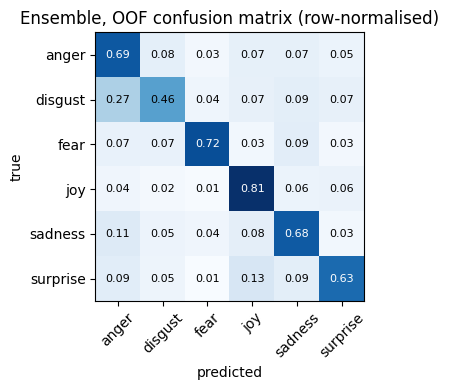

In [14]:
import matplotlib.pyplot as plt
final_oof = nested if use_bias else lo.argmax(1)                      # honest (nested) predictions for the report
rows = [(n, preds[n]["oof"].argmax(1)) for n in names] + [(f"ensemble: {k} (cross-fitted)", v.argmax(1)) for k, v in cv.items()]
rows += [("ensemble + class bias (nested CV)", nested)]
print(pd.DataFrame([(n, f1_score(y, p, average="macro"), accuracy_score(y, p)) for n, p in rows],
                   columns=["model", "OOF macro-F1", "OOF accuracy"]).round(4).to_string(index=False))
for part, mask in [("GoEmotions posts", is_ge), ("other posts", ~is_ge)] if is_ge.any() else []:
    print(f"{part}: {mask.sum()} train posts | final OOF macro-F1 {f1_score(y[mask], final_oof[mask], average='macro'):.4f}")
print(f"total time {(time.time() - T0) / 3600:.1f} h")

os.makedirs("pics", exist_ok=True)
cm = confusion_matrix(y, final_oof, normalize="true")
fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(6), LABELS, rotation=45); ax.set_yticks(range(6), LABELS)
for i in range(6):
    for j in range(6):
        ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if cm[i, j] > 0.5 else "black")
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title("Ensemble, OOF confusion matrix (row-normalised)")
plt.tight_layout(); plt.savefig("pics/confusion_matrix.png", dpi=150); plt.show()